# Serie I · Campo — 05. Datos propios: qué capturar y cómo diseñar los ensayos

**Pregunta 4 de la prueba:** ¿qué datos debería empezar a capturar el ingenio, y cómo diseñaría sus propios ensayos,
para tomar esta decisión (qué variedades ampliar y cada cuánto renovar) con datos propios en las próximas zafras?

**La respuesta tiene tres usos de los datos, en orden de rapidez:**
1. **Lo que ya existe:** todo ingenio registra cada corte de cada lote. Con eso se puede auditar desde la primera zafra
   **cuándo se renovó cada lote y si fue a tiempo** (sección 3), y cuánto pesa la distancia al ingenio (sección 4).
2. **El ambiente de cada lote:** la costa sur no es Louisiana. Estrato altitudinal, suelo, lluvia, viento y drenaje
   cambian a lo largo de la franja cañera; se agrupan los lotes en **zonas de manejo** (sección 5).
3. **Evidencia causal:** los registros comerciales no comparan variedades en igualdad de condiciones (cada variedad
   está donde alguien decidió sembrarla). Para eso hacen falta **ensayos propios**, dimensionados con la variabilidad
   real medida en Louisiana (sección 6).

**Fuentes.** Todo dato de Guatemala sale de fuentes públicas citadas. Lo que no está publicado se presenta como
**hipótesis de experto** que los datos del ingenio deben confirmar. Las demostraciones de código usan **datos
simulados** y así se rotulan: prueban que el método funciona, no describen a ningún ingenio.

In [1]:
import sys, json, re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.metrics import silhouette_score, adjusted_rand_score
warnings.filterwarnings("ignore", category=RuntimeWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from campo_data import load_raw, clean
from campo_economia import clone_curve
from campo_renovacion import (SupuestosMetricos, curva_metrica, margen_ciclo, reconstruir_ciclos, resumir_ciclos,
                              auditar, resumen_lotes, regla_lote, simular_portafolio, TCA_A_TCH, TRS_A_KG, ACRE_HA)
from campo_ensayos import componentes_varianza, potencia, fincas_necesarias, distancia_gower

FIG = ROOT / "outputs" / "figures"; TAB = ROOT / "outputs" / "tables"; MOD = ROOT / "outputs" / "models"
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
AZUL, NARANJA, AQUA, AMARILLO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#9a9993"
TINTA, TINTA2, REJILLA = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": REJILLA, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
})
def guardar(fig, nombre):
    fig.tight_layout(); fig.savefig(FIG / nombre, bbox_inches="tight"); plt.show()
SEED = 20261019
CURVAS = json.loads((MOD / "serie1_curvas.json").read_text(encoding="utf-8"))
REC = pd.read_csv(TAB / "serie1_recomendacion.csv", index_col=0)
TOP3 = REC.index[:3].tolist()

## 1. Contexto de Guatemala (fuentes públicas)

**La zona cañera** está en la costa sur (Retalhuleu, Suchitepéquez, Escuintla y Santa Rosa, extendiéndose hacia
Jutiapa) y ocupaba unas 230,000 ha en la zafra 2009-2010 [1]. CENGICAÑA la divide en **cuatro estratos
altitudinales**, con condiciones muy distintas [1]:

| Estrato | Altitud (msnm) | Lluvia media (mm/año) | Viento medio (km/h) |
|---|---|---|---|
| Litoral | < 40 | 1,500 | 8.7 |
| Bajo | 40-100 | 1,900 | 6.2 |
| Medio | 100-300 | 3,700 | 6.8 |
| Alto | > 300 | 4,100 | 5.2 |

- **Suelos [1]:** Mollisoles 40 % (litoral y planicie costera), Andisoles 26 % (zonas altas y medias, volcánicos),
  Entisoles 16 % (aluviales, con subsuelo arenoso), Inceptisoles 11 %. CENGICAÑA define 13 grupos de manejo de suelos;
  los dos mayores son Mollisoles secos (37.1 %) y **Entisoles con capas de arena (19.9 %)**.
- **Zonas agroecológicas [1]:** la primera aproximación de CENGICAÑA cruza los 13 grupos de suelo con grupos de balance
  hídrico (octubre-mayo) y obtiene **44 zonas**. No encontramos en fuentes públicas una clasificación de 7-8 regiones;
  si existe una referencia publicada, se incorpora igual.
- **Variedad × ambiente en Guatemala [2]:** con datos comerciales de un ingenio, las variedades difieren en 9 de 12
  combinaciones de estrato y suelo, y la mejor cambia según el estrato (CP72-2086 fue la mejor en el litoral).
- **CP72-2086, la variedad "caballito de batalla":** la más sembrada del país durante años (33.4 % del área censada en
  la zafra 2015-16) y moderadamente susceptible a roya naranja [3]. En la zafra 2020-21 la guatemalteca CG02-163 la
  superó por primera vez (25.4 % contra 23.1 %) [4].

**Por qué importa para el método.** Louisiana es plana y casi al nivel del mar; Guatemala va del litoral arenoso a
laderas volcánicas con casi 3 veces más lluvia. La interacción variedad × ambiente será **mayor** que la medida en
Louisiana: los tamaños de ensayo de la sección 6 son un **mínimo**.

[1] Melgar, M. et al. (eds.) (2012). *El Cultivo de la Caña de Azúcar en Guatemala*, cap. II. CENGICAÑA.
[2] Ralda, R. (2015). *Evaluación del rendimiento comercial de variedades de caña de azúcar según estratos
altitudinales y tipos de suelo*. Zamorano.
[3] Prensa Libre (2016). "Siembran más variedades de caña de azúcar" (censo varietal CENGICAÑA, zafra 2015-16).
[4] ASAZGUA / Guatecaña (2021). "Por primera vez una variedad de caña guatemalteca lidera en la agroindustria".

### Hipótesis de experto (a confirmar con datos del ingenio)

Criterio de campo del candidato, no publicado; cada uno se convierte en una prueba con los datos propios:

| # | Hipótesis | Con qué datos se confirma | Análisis |
|---|---|---|---|
| E1 | El litoral con bancos de arena retiene menos agua: rinden mejor las variedades tolerantes a sequía o con riego | grupo de suelo, riego, TCH por variedad | interacción variedad × grupo de suelo (sección 5-6) |
| E2 | El oriente (Santa Rosa, Taxisco) es más seco y con vientos distintos al occidente (Retalhuleu) | clima diario por estación | zonas de manejo con lluvia y viento (sección 5) |
| E3 | Las zonas altas cerca de los volcanes (300-400 msnm) tienen otros suelos y más lluvia | altitud, grupo de suelo | estrato como variable de la zona |
| E4 | Hay lotes que nunca se renovaron, otros que se renuevan de más y otros tarde | historial de cortes | auditoría de renovaciones (sección 3) |
| E5 | La distancia al ingenio encarece cosecha y renovación, y cambia la economía del lote | distancia, costos por lote | economía por distancia (sección 4) |
| E6 | Hay variedades generalistas y otras especialistas de una zona | ensayos en varias zonas | estabilidad y respuesta (pregunta 3) por zona |

## 2. Qué datos capturar: modelo mínimo en PostgreSQL

`sql/esquema_campo.sql` define 11 tablas y una vista. Cada regla responde a un problema real encontrado en el dataset
de Louisiana: números con coma decimal guardados como texto, unidades que cambian entre años, doble captura, valores
imposibles y nombres de finca escritos de dos formas.

| Tabla | Una fila por | Campos clave | Para qué |
|---|---|---|---|
| `finca` | finca | altitud, **estrato**, **distancia al ingenio**, coordenadas | zonificar y costear |
| `lote` | lote | área, **grupo de suelo**, **drenaje**, riego, polígono | zonificar |
| `siembra` | renovación | fecha de siembra, variedad | **reconstruir ciclos sin adivinar** |
| `cosecha` | lote × corte | zafra, fecha, **número de corte**, toneladas, área, rendimiento, fibra, edad, tercio de zafra, tipo de cosecha | todo lo demás |
| `estacion`, `lote_estacion`, `clima_diario` | estación × día | lluvia, temperatura, radiación, viento | explicar el error de nivel (pregunta 2) |
| `manejo` | aplicación | fertilización, riego, madurante | separar variedad de manejo |
| `costo_lote` | lote × zafra × concepto | corte, alce, transporte, renovación | economía por lote |
| `ensayo`, `parcela_ensayo` | parcela × corte | variedad, testigo, repetición, TCH, rendimiento, roya | ensayos propios (sección 6) |

**Verificado de punta a punta** (script `tests/test_esquema_postgres.py`, con PostgreSQL 16): el esquema se crea,
carga un portafolio simulado, **rechaza** la doble captura, un rendimiento imposible, un número con coma decimal y un
estrato inexistente, y la vista `v_cosecha_ciclo` alimenta la auditoría de la sección 3 con los mismos resultados que
pandas.

**Tres campos que más se pierden y más valen:** el número de corte (o la siembra a la que pertenece cada cosecha), el
grupo de suelo del lote y el clima diario. Sin el primero no se reconstruyen bien los ciclos (sección 3); sin los otros
dos el 77 % del error de la pregunta 2 sigue sin explicación.

In [2]:
sql = (ROOT / "sql" / "esquema_campo.sql").read_text(encoding="utf-8")
tablas = re.findall(r"CREATE TABLE (\w+)", sql); vistas = re.findall(r"CREATE VIEW (\w+)", sql)
reglas = len(re.findall(r"CHECK \(", sql)) + len(re.findall(r"UNIQUE \(", sql))
print(f"{len(tablas)} tablas: {', '.join(tablas)}"); print(f"vista: {', '.join(vistas)} | {reglas} reglas CHECK/UNIQUE")

11 tablas: finca, lote, siembra, cosecha, estacion, lote_estacion, clima_diario, manejo, costo_lote, ensayo, parcela_ensayo
vista: v_cosecha_ciclo | 31 reglas CHECK/UNIQUE


## 3. Auditoría de renovaciones con los registros que ya existen

Con una fila por lote y corte se reconstruye la historia de cada lote: plantía → socas → renovación → plantía. Cada
ciclo cerrado se compara con el **ciclo óptimo** de la pregunta 1 (4 cortes con los supuestos de la prueba; el óptimo
es plano entre 3 y 5, por eso la tolerancia es ±1 corte):

- **Renovación temprana:** se renovó con 2 cortes o menos → se pagó la renovación antes de recuperarla.
- **A tiempo:** 3-5 cortes.
- **Tardía:** 6 o más → se cosecharon socas que ya no pagaban.
- **Ciclo abierto vencido / sin renovación en el período:** el lote sigue cortándose más allá del óptimo.

Además, para cada lote en pie, una **regla de reemplazo propia del lote**: se mantiene la soca mientras el margen
esperado del próximo corte (con la caída **de ese lote**, encogida hacia la típica) supere el margen promedio anual
de un ciclo nuevo en ese mismo lote. Así se respeta que hay lotes que aguantan más y otros que caen rápido.

**Demostración con datos SIMULADOS**: 60 fincas × 8 lotes × 12 zafras, con políticas de renovación conocidas, para
comprobar que el método las recupera. Las cifras no describen a ningún ingenio.

In [3]:
S = SupuestosMetricos()
curva = curva_metrica(CURVAS["curva_testigos"])
m_corte, prom = margen_ciclo(curva["tch"].to_numpy(), curva["rend"].to_numpy(), S)
OPTIMO = int(np.argmax(prom)) + 1
print(f"Supuestos de la prueba en métrico: US${S.precio_kg:.3f}/kg azúcar · US${S.corte_t:.2f}/t caña · "
      f"US${S.mantenimiento_ha:,.0f}/ha/año · US${S.renovacion_ha:,.0f}/ha renovación")
print(f"Ciclo óptimo del testigo: {OPTIMO} cortes, US${prom.max():,.0f}/ha/año "
      f"(= US${prom.max() * ACRE_HA:,.1f}/acre/año, igual que la pregunta 1)")

cos, verdad = simular_portafolio(curva, semilla=SEED)
cic = reconstruir_ciclos(cos); res = resumir_ciclos(cic); aud = auditar(res, OPTIMO)
v = aud.merge(verdad, on=["finca", "lote"])
print(f"\nSIMULADO · {cos['lote'].nunique()} lotes, {len(cos):,} cortes, {len(res)} ciclos")
print("Ciclos cerrados: política real (filas) vs clasificación de la auditoría (columnas)")
display(pd.crosstab(v.loc[v["cerrado"], "politica"], v.loc[v["cerrado"], "estado"]))
lotes = resumen_lotes(aud, min(cos["zafra"])).join(verdad.set_index(["finca", "lote"]))
display(pd.crosstab(lotes["politica"], lotes["diagnostico"]))

Supuestos de la prueba en métrico: US$0.441/kg azúcar · US$15.43/t caña · US$865/ha/año · US$2,718/ha renovación
Ciclo óptimo del testigo: 4 cortes, US$1,300/ha/año (= US$526.3/acre/año, igual que la pregunta 1)

SIMULADO · 480 lotes, 5,760 cortes, 1623 ciclos
Ciclos cerrados: política real (filas) vs clasificación de la auditoría (columnas)


estado,renovación a tiempo,renovación tardía,renovación temprana
politica,,,
a tiempo,629,0,0
tardía,0,135,0
temprana,0,0,379


diagnostico,renovación en orden,renueva antes de tiempo,renueva tarde,sin renovación en el período
politica,,,,
a tiempo,232,0,0,0
nunca,0,0,0,89
tardía,0,0,89,0
temprana,0,70,0,0


In [4]:
# ¿Y si el ingenio no registra el número de corte? Se pierden las renovaciones que repiten variedad
sin_corte = resumir_ciclos(reconstruir_ciclos(cos.drop(columns="corte")))
perdidas = 1 - (len(sin_corte) - cos["lote"].nunique()) / (len(res) - cos["lote"].nunique())
print(f"Sin número de corte se detectan {len(sin_corte) - cos['lote'].nunique()} de "
      f"{len(res) - cos['lote'].nunique()} renovaciones: se pierde el {perdidas:.0%} (las que vuelven a sembrar la misma variedad)")

regla = regla_lote(cic, curva, S).merge(verdad, on=["finca", "lote"])
display(regla.groupby(["politica"])["decision"].value_counts().unstack().fillna(0).astype(int))

Sin número de corte se detectan 856 de 1143 renovaciones: se pierde el 25% (las que vuelven a sembrar la misma variedad)


decision,otro corte,renovar
politica,,
a tiempo,156,76
nunca,0,89
tardía,33,56
temprana,68,2


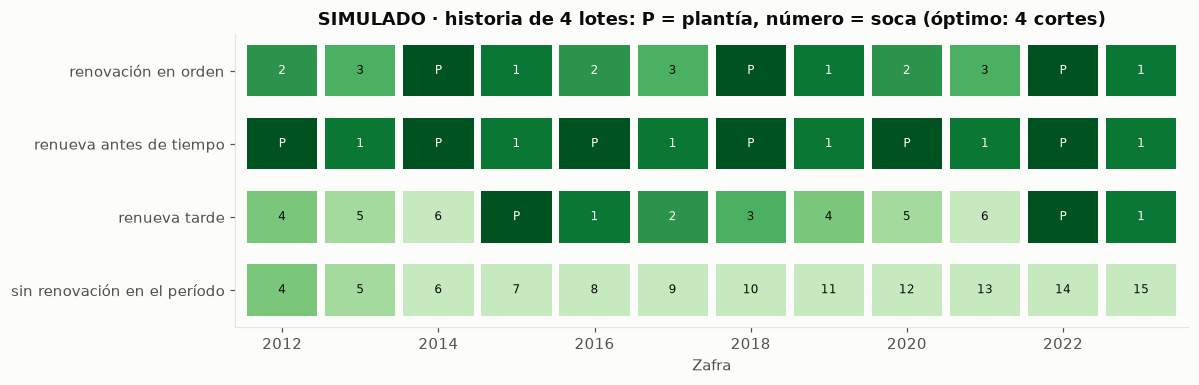

In [5]:
# Cómo se ve la auditoría: un lote simulado de cada tipo
ejemplos = [lotes.index[lotes["diagnostico"] == d][0] for d in
            ["renovación en orden", "renueva antes de tiempo", "renueva tarde", "sin renovación en el período"]]
fig, ax = plt.subplots(figsize=(11, 3.6))
for i, (f, l) in enumerate(ejemplos):
    x = cic[(cic["finca"] == f) & (cic["lote"] == l)]
    for _, r in x.iterrows():
        tono = min(r["corte"], 6) / 6
        ax.add_patch(plt.Rectangle((r["zafra"] - 0.45, i - 0.35), 0.9, 0.7, color=plt.cm.Greens(0.25 + 0.7 * (1 - tono)), lw=0))
        ax.text(r["zafra"], i, "P" if r["corte"] == 0 else int(r["corte"]), ha="center", va="center", fontsize=8,
                color="#fcfcfb" if r["corte"] <= 2 else TINTA)
ax.set_yticks(range(len(ejemplos)), [lotes.loc[e, "diagnostico"] for e in ejemplos])
ax.set_xlim(cos["zafra"].min() - 0.6, cos["zafra"].max() + 0.6); ax.set_ylim(len(ejemplos) - 0.5, -0.5)
ax.set_xlabel("Zafra"); ax.grid(False)
ax.set_title(f"SIMULADO · historia de 4 lotes: P = plantía, número = soca (óptimo: {OPTIMO} cortes)")
guardar(fig, "serie1_25_auditoria_ciclos.png")

## 4. La distancia al ingenio: ¿cambia cuándo renovar?

La distancia sube el **costo por tonelada** (corte, alce y transporte) y, con más mano de obra y logística, el **costo
de renovar**. Se recalcula la economía de la pregunta 1 (mismas curvas) en una grilla de ambos costos. Los montos de la
grilla son escenarios, no datos de un ingenio: la base es el supuesto de la prueba.

In [6]:
def curva_var(v):
    p = CURVAS["variedades"][v]
    cc = clone_curve(pd.DataFrame(CURVAS["curva_testigos"]).set_index("corte")[["mult", "sugar", "trs"]],
                     p["a"], p["b"], p["trs_rel"], int(p["ultimo_corte_medido"]))
    return (cc["tca"] * TCA_A_TCH).to_numpy(), (cc["trs"] * TRS_A_KG).to_numpy()
CURV = {"Testigo promedio": (curva["tch"].to_numpy(), curva["rend"].to_numpy()), **{v: curva_var(v) for v in TOP3}}

costos_t = np.arange(10, 61, 1.0)
filas = []
for nombre, (tch, rend) in CURV.items():
    for ct in costos_t:
        _, pr = margen_ciclo(tch, rend, SupuestosMetricos(corte_t=ct))
        filas.append({"variedad": nombre, "costo_t": ct, "margen": pr.max(), "ciclo": int(np.argmax(pr)) + 1})
DIST = pd.DataFrame(filas)
def costo_equilibrio(tch, rend, lo=10.0, hi=100.0):
    """Costo por tonelada en que el margen del mejor ciclo llega a 0 (bisección)."""
    for _ in range(60):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if margen_ciclo(tch, rend, SupuestosMetricos(corte_t=mid))[1].max() > 0 else (lo, mid)
    return hi
equilibrio = pd.Series({nombre: costo_equilibrio(*cv) for nombre, cv in CURV.items()})
print("Costo por tonelada en que el mejor ciclo deja de cubrir costos (US$/t):"); display(equilibrio.round(1).to_frame("US$/t"))
t = DIST[DIST["variedad"] == "Testigo promedio"]
print("Ciclo óptimo según el costo por tonelada (renovación de la prueba):", DIST.groupby("variedad")["ciclo"].agg(["min", "max"]).to_dict("index"))
print(f"El testigo pasa a 5 cortes desde US${t.loc[t['ciclo'] == 5, 'costo_t'].min():.0f}/t (con la renovación de la prueba, US${S.renovacion_ha:,.0f}/ha)")
cae = DIST.groupby("variedad").apply(lambda g: -np.polyfit(g["costo_t"], g["margen"], 1)[0], include_groups=False)
print("Margen que se pierde por cada US$1/t adicional (US$/ha/año):", cae.round(0).to_dict())

renov = np.arange(1500, 4600, 250.0)
grid = pd.DataFrame([[int(np.argmax(margen_ciclo(*CURV["Testigo promedio"], SupuestosMetricos(corte_t=ct, renovacion_ha=rv))[1])) + 1
                      for ct in np.arange(10, 31, 2.0)] for rv in renov], index=renov, columns=np.arange(10, 31, 2.0))
print("Ciclo óptimo del testigo: filas = costo de renovación (US$/ha), columnas = costo por tonelada (US$/t)")
display(grid)

Costo por tonelada en que el mejor ciclo deja de cubrir costos (US$/t):


,US$/t
Testigo promedio,35.9
HOCP14-885,43.2
HOL15-508,43.6
L15-306,41.3


Ciclo óptimo según el costo por tonelada (renovación de la prueba): {'HOCP14-885': {'min': 4, 'max': 5}, 'HOL15-508': {'min': 4, 'max': 5}, 'L15-306': {'min': 4, 'max': 5}, 'Testigo promedio': {'min': 4, 'max': 5}}
El testigo pasa a 5 cortes desde US$37/t (con la renovación de la prueba, US$2,718/ha)
Margen que se pierde por cada US$1/t adicional (US$/ha/año): {'HOCP14-885': 71.0, 'HOL15-508': 68.0, 'L15-306': 69.0, 'Testigo promedio': 62.0}
Ciclo óptimo del testigo: filas = costo de renovación (US$/ha), columnas = costo por tonelada (US$/t)


,10.0,12.0,14.0,16.0,18.0,20.0,22.0,24.0,26.0,28.0,30.0
1500.0,3,3,3,3,3,3,3,3,3,3,3
1750.0,3,3,3,3,3,3,3,4,4,4,4
2000.0,3,3,3,4,4,4,4,4,4,4,4
2250.0,4,4,4,4,4,4,4,4,4,4,4
2500.0,4,4,4,4,4,4,4,4,4,4,4
2750.0,4,4,4,4,4,4,4,4,4,4,4
3000.0,4,4,4,4,4,4,4,4,4,4,4
3250.0,4,4,4,4,4,4,4,4,5,5,5
3500.0,4,4,4,4,4,4,5,5,5,5,5
3750.0,4,4,4,4,5,5,5,5,5,5,5


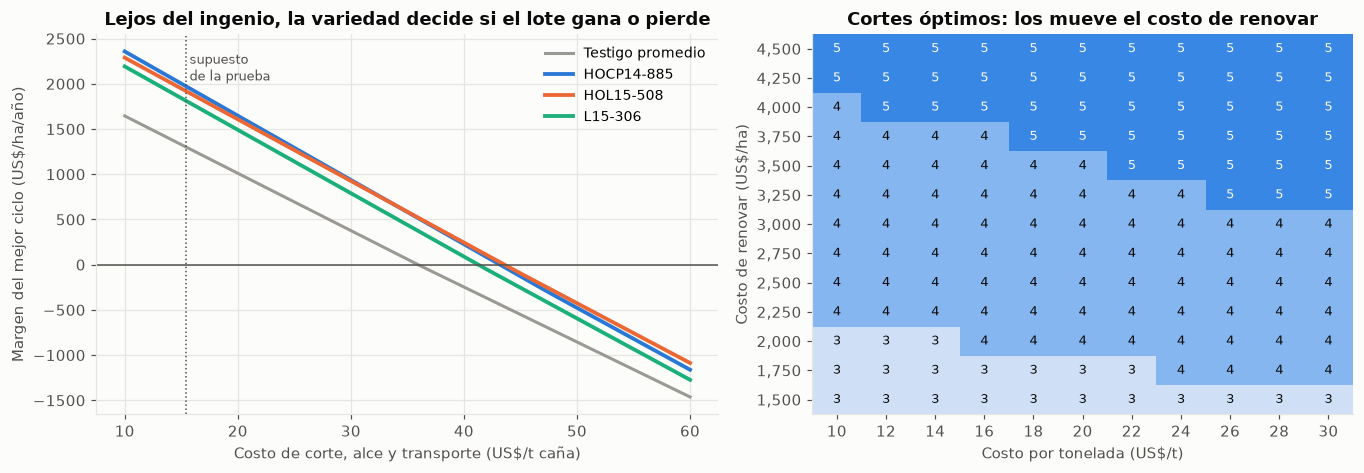

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
colores = [GRIS, AZUL, NARANJA, AQUA]
for (nombre, g), col in zip(DIST.groupby("variedad", sort=False), colores):
    ax.plot(g["costo_t"], g["margen"], color=col, label=nombre, lw=2.5 if nombre != "Testigo promedio" else 2)
ax.axhline(0, color=TINTA2, lw=1); ax.axvline(S.corte_t, color=TINTA2, lw=1, ls=":")
ax.text(S.corte_t + 0.3, ax.get_ylim()[1] * 0.92, "supuesto\nde la prueba", fontsize=8.5, color=TINTA2, va="top")
ax.set_xlabel("Costo de corte, alce y transporte (US$/t caña)"); ax.set_ylabel("Margen del mejor ciclo (US$/ha/año)")
ax.set_title("Lejos del ingenio, la variedad decide si el lote gana o pierde"); ax.legend(frameon=False, fontsize=9)
ax = axes[1]
vals = grid.to_numpy()
cmap = plt.matplotlib.colors.ListedColormap(["#cfe0f6", "#86b6ef", "#3987e5", "#1c5cab"])
ax.imshow(vals, cmap=cmap, vmin=2.5, vmax=6.5, aspect="auto", origin="lower")
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        ax.text(j, i, vals[i, j], ha="center", va="center", fontsize=8.5, color="#fcfcfb" if vals[i, j] >= 5 else TINTA)
ax.set_xticks(range(grid.shape[1]), [f"{c:.0f}" for c in grid.columns]); ax.set_yticks(range(grid.shape[0]), [f"{r:,.0f}" for r in grid.index])
ax.set_xlabel("Costo por tonelada (US$/t)"); ax.set_ylabel("Costo de renovar (US$/ha)"); ax.grid(False)
ax.set_title("Cortes óptimos: los mueve el costo de renovar")
guardar(fig, "serie1_24_distancia.png")

**Lectura.**
- **El costo por tonelada casi no cambia cuándo renovar.** Con el costo de renovar de la prueba, el óptimo del testigo
  sigue en 4 cortes hasta US$36/t y solo pasa a 5 desde US$37/t, cuando ya no cubre costos. Lo que sí hace es bajar
  el margen: cada US$1/t
  adicional cuesta ~US$62-71/ha/año.
- **Lo que mueve el ciclo es el costo de renovar.** Con renovaciones de US$1,500/ha conviene renovar cada 3 cortes (y
  hasta ~US$2,000/ha si la tonelada es barata); desde ~US$3,250-4,250/ha (según el costo por tonelada), estirar a 5. Si en las fincas lejanas renovar sale más
  caro (traslado de semilla, maquinaria, mano de obra), su ciclo óptimo es más largo que el de las cercanas.
- **En fincas lejanas la variedad es la decisión principal.** El testigo deja de cubrir costos a ~US$36/t; las tres
  recomendadas aguantan hasta US$41-44/t. Con caña cara de transportar, solo una variedad superior hace rentable el
  lote.
- **Implicación para los datos:** registrar el costo real por lote (`costo_lote`) y la distancia (`finca`) permite
  calcular el ciclo óptimo **por zona de costos**, no uno solo para todo el ingenio.

## 5. Zonificación de lotes: agrupar por ambiente, no por nombre de finca

**Variables** (por lote): altitud, lluvia anual, viento, grupo de suelo y drenaje. Mezclan números y categorías, así que
se usa la **distancia de Gower** (cada variable aporta lo mismo, numéricas escaladas por su rango) y un agrupamiento
jerárquico. **La distancia al ingenio no entra:** define costos, no qué variedad se adapta; se usa en la sección 4.

**Uso de las zonas:** la zona reemplaza a la "finca de Louisiana" en todo lo anterior: ventaja de cada variedad contra
testigos **por zona** (pregunta 1), nivel de la zona en el modelo de la pregunta 2 y respuesta al ambiente (pregunta 3).
Lotes de la misma zona comparten historia: un lote nuevo hereda la recomendación de su zona hasta tener la suya.

**Demostración con lotes SIMULADOS:** cuatro perfiles de ambiente construidos a partir de los promedios públicos de
CENGICAÑA por estrato (dos combinan estratos vecinos), con ruido y 10 % de etiquetas cambiadas. Se comprueba que el método recupera los perfiles.

In [8]:
rng = np.random.default_rng(SEED)
PERFILES = {   # (altitud msnm, lluvia mm, viento km/h, suelo, drenaje) — a partir de los promedios por estrato [1]
    "litoral arenoso":      ((5, 38),    1500, 8.7, "entisol con arena", "excesivo"),
    "planicie seca":        ((15, 95),   1700, 7.4, "mollisol seco",     "bueno"),
    "bajo encharcable":     ((40, 100),  1900, 6.2, "inceptisol",        "encharcable"),
    "medio-alto volcánico": ((110, 450), 3900, 6.0, "andisol",           "bueno"),
}
filas = []
for zona, ((a0, a1), ll, vi, su, dr) in PERFILES.items():
    for _ in range(60):
        filas.append({"zona_real": zona, "altitud": rng.uniform(a0, a1), "lluvia": rng.normal(ll, 250),
                      "viento": rng.normal(vi, 0.8),
                      "suelo": su if rng.random() > 0.1 else rng.choice([p[3] for p in PERFILES.values()]),
                      "drenaje": dr if rng.random() > 0.1 else rng.choice(["bueno", "encharcable", "excesivo"]),
                      "distancia_km": rng.uniform(5, 90)})
LOTES = pd.DataFrame(filas)
LOTES["estrato"] = pd.cut(LOTES["altitud"], [-1, 40, 100, 300, 2000], labels=["litoral", "bajo", "medio", "alto"])
Dg = distancia_gower(LOTES, ["altitud", "lluvia", "viento"], ["suelo", "drenaje"])
Zl = linkage(squareform(Dg, checks=False), method="average")
sil = {k: silhouette_score(Dg, fcluster(Zl, k, "maxclust"), metric="precomputed") for k in range(2, 8)}
k_z = max(sil, key=sil.get)
LOTES["zona"] = fcluster(Zl, k_z, "maxclust")
print("SIMULADO · silueta por número de zonas:", {k: round(v, 2) for k, v in sil.items()}, "→", k_z, "zonas")
print(f"Coincidencia con los perfiles reales: ARI = {adjusted_rand_score(LOTES['zona_real'], LOTES['zona']):.2f}")
display(pd.crosstab(LOTES["zona_real"], LOTES["zona"]))

SIMULADO · silueta por número de zonas: {2: 0.48, 3: 0.58, 4: 0.73, 5: 0.71, 6: 0.72, 7: 0.72} → 4 zonas
Coincidencia con los perfiles reales: ARI = 0.90


zona,1,2,3,4
zona_real,,,,
bajo encharcable,2,1,0,57
litoral arenoso,0,59,0,1
medio-alto volcánico,60,0,0,0
planicie seca,1,1,55,3


## 6. Ensayos propios: cuántas fincas, años y repeticiones

Con los ensayos de etapa 5 de Louisiana se estiman cuatro fuentes de variación de la **diferencia entre dos
variedades** (escala log del azúcar por área): variedad × finca, variedad × año, variedad × lote-año y error de
parcela entre repeticiones. Con ellas se calcula la potencia de un ensayo para detectar una ventaja real.

Un ensayo típico: una cohorte sembrada en *L* fincas y seguida **4 cortes** (plantía + 3 socas = 4 años de cosecha),
con *R* repeticiones.

In [9]:
d5 = clean(load_raw(ROOT / "data" / "raw" / "All_Genotypes_2010_onwards.csv"))[0].query("STAGE == 5")
VC = componentes_varianza(d5)
comp = pd.DataFrame({"varianza": [VC["GL"], VC["GY"], VC["GLY"], VC["e"]],
                     "desvío (%)": [100 * np.sqrt(VC[k]) for k in ["GL", "GY", "GLY", "e"]]},
                    index=["variedad × finca", "variedad × año", "variedad × lote-año", "error de parcela (por repetición)"])
display(comp.round(4))
print(f"Repeticiones promedio en Louisiana: {VC['r_media']:.1f}")
_ = (MOD / "serie1_componentes_varianza.json").write_text(json.dumps(VC, indent=1), encoding="utf-8")

,varianza,desvío (%)
variedad × finca,0.0017,4.1267
variedad × año,0.0008,2.8547
variedad × lote-año,0.0059,7.6560
error de parcela (por repetición),0.0238,15.4153


Repeticiones promedio en Louisiana: 3.0


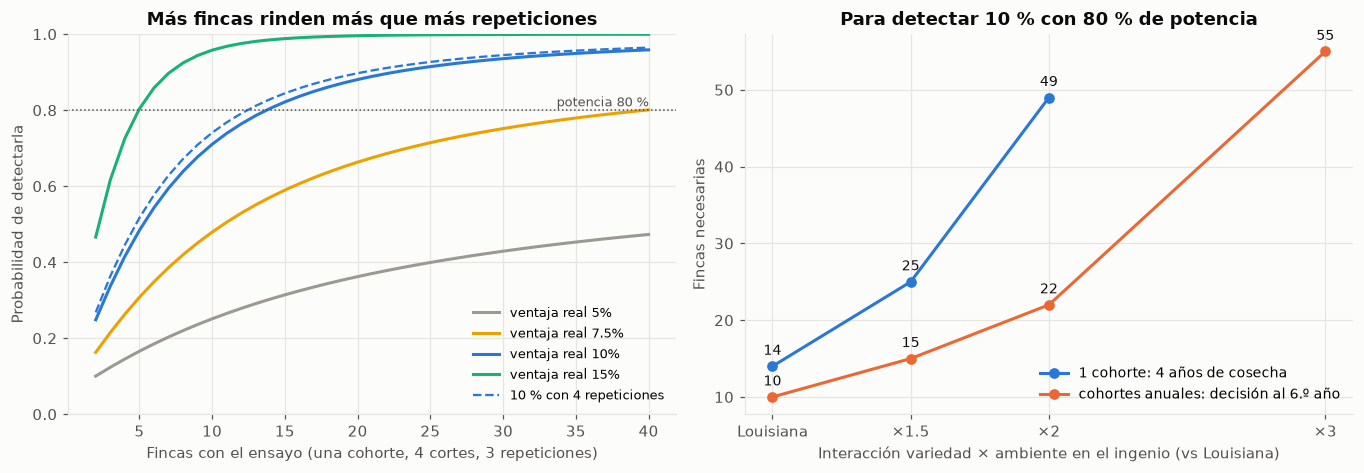

Fincas necesarias (3 repeticiones, potencia 80 %; vacío = no se alcanza con 200 fincas):


,ventaja 5%,ventaja 7.5%,ventaja 10%,ventaja 15%
"4 años de cosecha, interacción ×1",NaN,40.0,14,5
"4 años de cosecha, interacción ×1.5",NaN,NaN,25,8
"4 años de cosecha, interacción ×2",NaN,NaN,49,10
"6 años de cosecha, interacción ×1",NaN,21.0,10,4
"6 años de cosecha, interacción ×1.5",NaN,42.0,15,6
"6 años de cosecha, interacción ×2",NaN,109.0,22,7


Desde 15 fincas × 3 rep. (potencia 82%, ventaja 10 %): +5 fincas → +5.9 pp; +1 repetición → +2.3 pp (2.6 veces más por fincas, mismo número de parcelas)
Recomendación de 20 fincas × 3 rep. con 6 años de cosecha (ventaja 10 %): potencia 96% con interacción ×1, 87% con interacción ×1.5, 78% con interacción ×2


In [10]:
L_ = np.arange(2, 41)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
ax = axes[0]
for d, col in zip([0.05, 0.075, 0.10, 0.15], [GRIS, AMARILLO, AZUL, AQUA]):
    ax.plot(L_, [potencia(d, VC, L, 4, 3) for L in L_], color=col, label=f"ventaja real {d:.1%}".replace(".0%", "%"))
ax.plot(L_, [potencia(0.10, VC, L, 4, 4) for L in L_], color=AZUL, ls="--", lw=1.5, label="10 % con 4 repeticiones")
ax.axhline(0.8, color=TINTA2, lw=1, ls=":"); ax.text(40, 0.81, "potencia 80 %", ha="right", fontsize=8.5, color=TINTA2)
ax.set_xlabel("Fincas con el ensayo (una cohorte, 4 cortes, 3 repeticiones)"); ax.set_ylabel("Probabilidad de detectarla")
ax.set_ylim(0, 1); ax.set_title("Más fincas rinden más que más repeticiones"); ax.legend(frameon=False, fontsize=8.5, loc="lower right")
ax = axes[1]
fac = [1, 1.5, 2, 3]
for Y, col, lab in [(4, AZUL, "1 cohorte: 4 años de cosecha"), (6, NARANJA, "cohortes anuales: decisión al 6.º año")]:
    req = [fincas_necesarias(0.10, VC, Y, 3, factor_gxe=f) for f in fac]
    ax.plot(fac, req, color=col, marker="o", label=lab)
    for f, r in zip(fac, req):
        if not np.isnan(r): ax.text(f, r + 1.5, f"{r:.0f}", ha="center", fontsize=9, color=TINTA)
ax.set_xticks(fac, ["Louisiana", "×1.5", "×2", "×3"]); ax.set_xlabel("Interacción variedad × ambiente en el ingenio (vs Louisiana)")
ax.set_ylabel("Fincas necesarias"); ax.set_title("Para detectar 10 % con 80 % de potencia"); ax.legend(frameon=False, fontsize=9)
guardar(fig, "serie1_23_tamano_ensayos.png")

tabla_pot = pd.DataFrame({f"ventaja {d:.1%}".replace(".0%", "%"): {f"{Y} años de cosecha, interacción ×{f}": fincas_necesarias(d, VC, Y, 3, factor_gxe=f)
                          for Y in [4, 6] for f in [1, 1.5, 2]} for d in [0.05, 0.075, 0.10, 0.15]})
print("Fincas necesarias (3 repeticiones, potencia 80 %; vacío = no se alcanza con 200 fincas):"); display(tabla_pot)
tabla_pot.to_csv(TAB / "serie1_tamano_ensayos.csv")
# Mismo esfuerzo extra (+33 % de parcelas): 5 fincas más o 1 repetición más, desde 15 fincas × 3 repeticiones
base_p = potencia(0.10, VC, 15, 4, 3)
mas_fincas, mas_rep = potencia(0.10, VC, 20, 4, 3) - base_p, potencia(0.10, VC, 15, 4, 4) - base_p
print(f"Desde 15 fincas × 3 rep. (potencia {base_p:.0%}, ventaja 10 %): +5 fincas → +{mas_fincas * 100:.1f} pp; "
      f"+1 repetición → +{mas_rep * 100:.1f} pp ({mas_fincas / mas_rep:.1f} veces más por fincas, mismo número de parcelas)")
POT20 = {f: potencia(0.10, VC, 20, 6, 3, factor_gxe=f) for f in [1, 1.5, 2]}
print("Recomendación de 20 fincas × 3 rep. con 6 años de cosecha (ventaja 10 %): potencia "
      + ", ".join(f"{p:.0%} con interacción ×{f}" for f, p in POT20.items()))
ej_lotes = {lotes.loc[e, "diagnostico"]: cic[(cic["finca"] == e[0]) & (cic["lote"] == e[1])][["zafra", "corte"]].astype(int).values.tolist()
            for e in ejemplos}
resumen4 = {"componentes": VC, "optimo": OPTIMO, "supuestos_metricos": S.__dict__,
            "auditoria": {"lotes": int(cos["lote"].nunique()), "cortes": int(len(cos)), "ciclos": int(len(res)),
                          "cerrados_bien": int((v.loc[v["cerrado"], "estado"].map({"renovación temprana": "temprana", "renovación a tiempo": "a tiempo",
                                                "renovación tardía": "tardía"}) == v.loc[v["cerrado"], "politica"]).sum()),
                          "cerrados": int(v["cerrado"].sum()), "perdidas_sin_corte": float(perdidas), "ejemplos": ej_lotes},
              "distancia": {"equilibrio": equilibrio.to_dict(), "pasa_a_5": float(t.loc[t["ciclo"] == 5, "costo_t"].min()),
                            "pierde_por_dolar": cae.round(1).to_dict()},
              "zonas": {"k": int(k_z), "ari": float(adjusted_rand_score(LOTES["zona_real"], LOTES["zona"]))},
              "potencia_20_fincas_6_anios": {str(f): float(p) for f, p in POT20.items()},
            "tamanos": {k: {c: (None if pd.isna(x) else float(x)) for c, x in r.items()} for k, r in tabla_pot.to_dict("index").items()}}
_ = (MOD / "serie1_resumen_p4.json").write_text(json.dumps(resumen4, indent=1, ensure_ascii=False, default=float), encoding="utf-8")

**Lectura.**
- **La repetición no es el cuello de botella:** el error de parcela se divide entre todas las fincas y años; lo que no
  se promedia es la interacción variedad × ambiente. Con el mismo número de parcelas extra (+33 %), sumar 5 fincas da
  2.6 veces más potencia que sumar una repetición con la interacción de Louisiana (celda anterior); si la de Guatemala
  es mayor, la diferencia a favor de las fincas crece.
- **Diferencias de 5 % no se pueden separar del ruido** con una cohorte: la interacción variedad × año pone un piso que
  no baja con más fincas. Con datos propios, el ingenio puede decidir con confianza sobre ventajas de ~10 % o más; para
  ventajas menores, la decisión debe combinar sus ensayos con la evidencia de CENGICAÑA y de los registros comerciales.
- **Guatemala necesitará más que Louisiana.** Para detectar 10 % con una sola cohorte hacen falta 14 fincas con la
  variabilidad de Louisiana, 25 si la interacción variedad × ambiente es 1.5 veces mayor y 49 si es el doble (plausible
  con 4 estratos y de 1,500 a 4,100 mm de lluvia). Con cohortes anuales y la decisión al acumular 6 años de cosecha,
  bastan 10, 15 y 22 fincas.

**Diseño recomendado**
1. **Estratificar por ambiente:** fincas repartidas en los 4 estratos de CENGICAÑA y en los grupos de suelo más
   extensos (mollisoles secos, entisoles arenosos, andisoles): **20 fincas por cohorte, 5 por estrato**, para
   estimar también la ventaja **dentro** de cada estrato (hipótesis E1, E3, E6). Con 6 años de cosecha, 20 fincas
   detectan una ventaja de 10 % con 87 % de potencia si la interacción es 1.5 veces la de Louisiana y con 78 % si es el
   doble (22 fincas llegan a 80 %). El tamaño se recalcula con la varianza propia al cerrar la primera cohorte.
2. **Una cohorte nueva cada año**, seguida hasta la soca 3-4: separa el efecto del año del de la edad y mide la
   longevidad, que es lo que más pesa en el margen (pregunta 1). La decisión firme sobre una candidata llega con ~6
   años de cosecha acumulados entre cohortes.
3. **Testigos fijos y estables:** la variedad de referencia de la industria (CP72-2086), la líder actual (CG02-163) y la
   comercial principal del ingenio, elegidos por estabilidad (pregunta 3: un testigo inestable vuelve ruidosa toda
   comparación). Los mismos testigos todos los años, como los 4 núcleo de Louisiana.
4. **Bloques completos al azar con 3 repeticiones** en ensayos de pocas variedades; diseño alfa-látice si se prueban
   muchas. Complementar con **franjas comerciales** de las candidatas avanzadas, cosechadas y pesadas como un lote normal.
5. **Medir en cada corte:** TCH, rendimiento, fibra (bagazo para cogeneración), población y peso de tallo, floración y
   roya naranja; clima diario de la estación más cercana.
6. **Analizar con el método de esta serie:** ventaja contra testigos del mismo ensayo y corte, curva de longevidad,
   economía del ciclo con costos por zona, y certeza por bootstrap de ensayos.

## 7. Hoja de ruta

| Cuándo | Qué | Con qué datos | Resultado |
|---|---|---|---|
| Zafra 1 (primeros 3 meses) | Ordenar los registros históricos en el modelo de la sección 2 | cosechas existentes | base única, con reglas de calidad |
| Zafra 1 | **Auditoría de renovaciones** y regla de reemplazo por lote | cosechas + número de corte | lista de lotes vencidos y de renovaciones adelantadas |
| Zafra 1 | Costos por lote y distancia: ciclo óptimo por zona de costo | `costo_lote`, `finca` | política de renovación por zona |
| Zafra 1-2 | **Zonificación** con estrato, suelo, lluvia, viento y drenaje | levantamiento de suelos, estaciones | zonas de manejo y variedad por zona (hipótesis) |
| Zafra 1 en adelante | **Ensayos propios** (una cohorte por año, 20 fincas) | ensayos | ventaja de cada candidata por zona, con certeza |
| Zafra 3-4 | Repetir las preguntas 1-3 con datos propios | todo lo anterior | recomendación de variedades y renovación del ingenio |

## 8. Evaluación gerencial

In [11]:
r = {(Y, f): fincas_necesarias(0.10, VC, Y, 3, factor_gxe=f) for Y in [4, 6] for f in [1, 2]}
print(f"Ensayos: detectar 10 % con 80 % de potencia requiere {r[(4, 1)]:.0f}-{r[(4, 2)]:.0f} fincas con una cohorte "
      f"(Louisiana a doble interacción) y {r[(6, 1)]:.0f}-{r[(6, 2)]:.0f} con cohortes anuales y 6 años de cosecha; "
      f"5 % no se alcanza con ningún tamaño razonable.")
print(f"Distancia: el testigo deja de cubrir costos a ~US${equilibrio['Testigo promedio']:.1f}/t; "
      + ", ".join(f"{v} a ~US${equilibrio[v]:.1f}/t" for v in TOP3) + ".")
print(f"Auditoría (simulada): clasificó correctamente todos los ciclos cerrados; sin número de corte se pierde el {perdidas:.0%} de las renovaciones.")

Ensayos: detectar 10 % con 80 % de potencia requiere 14-49 fincas con una cohorte (Louisiana a doble interacción) y 10-22 con cohortes anuales y 6 años de cosecha; 5 % no se alcanza con ningún tamaño razonable.
Distancia: el testigo deja de cubrir costos a ~US$35.9/t; HOCP14-885 a ~US$43.2/t, HOL15-508 a ~US$43.6/t, L15-306 a ~US$41.3/t.
Auditoría (simulada): clasificó correctamente todos los ciclos cerrados; sin número de corte se pierde el 25% de las renovaciones.


**Qué significa para el ingenio.** El ingenio no necesita esperar a tener ensayos para empezar a decidir con datos
propios: los registros de cosecha que ya tiene permiten auditar desde la primera zafra qué lotes están vencidos, cuáles
se renuevan de más y cuánto cuesta cada uno según su distancia. La pregunta de qué variedad sembrar en cada ambiente sí
necesita ensayos, porque los datos comerciales mezclan la variedad con el lugar donde se sembró.

**Decisión recomendada.**
1. Adoptar el modelo de datos mínimo (número de corte, siembra, grupo de suelo, drenaje, distancia, costos y clima).
2. Correr la auditoría de renovaciones y la regla de reemplazo por lote en la primera zafra.
3. Zonificar los lotes con la clasificación de CENGICAÑA y la información de suelos y clima propia.
4. Iniciar una cohorte anual de ensayos en 20 fincas (5 por estrato), con testigos estables
   (CP72-2086, CG02-163 y la comercial principal), seguidos hasta la soca 3-4.

**Impacto estimado.** La auditoría no requiere inversión nueva y ataca dos pérdidas directas: renovar antes de tiempo
(se paga la renovación sin recuperarla) y cosechar socas vencidas. Su tamaño depende de cuántos lotes caigan en cada
caso, que solo los registros del ingenio pueden decir. En fincas lejanas, elegir la variedad correcta separa un lote
rentable de uno con pérdida (sección 4).

**Riesgos.**
- *Registros incompletos:* sin número de corte o fecha de siembra no se reconstruyen bien los ciclos.
- *Variedad confundida con lugar:* en datos comerciales, una variedad "buena" puede estar solo en fincas buenas. Por
  eso la recomendación de variedad viene de ensayos, y los datos comerciales generan hipótesis.
- *Tiempo:* una cohorte tarda 4-5 años en medir longevidad. Mientras tanto, usar la evidencia de CENGICAÑA y la
  auditoría de renovaciones.
- *Validez de los tamaños:* calculados con la variabilidad de Louisiana; en Guatemala probablemente sea mayor. La primera
  cohorte permite recalcularlos con datos propios.

**Nivel de certeza.** Alta en el método (validado con datos simulados y con el esquema en PostgreSQL) y en que la
finca pesa más que la repetición. Media en los números de fincas: dependen de cuánto mayor sea la interacción variedad ×
ambiente en la costa sur.